# Week 8 — K-Nearest Neighbors and Distance Metrics

**Project:** Predicting Loan Repayment Risk Using LendingClub Data
**Target:** `target` = 1 if the loan was **charged off**, 0 if **fully paid** (definition and maturity filter in Week 1).
**Prediction point:** loan issuance, so only origination fields are used.

Questions:
1. Does a nonparametric "similar past loans" model separate charge-offs as well as the Week 4 logistic regression?
2. How do **k** and the **distance metric** (Euclidean, Manhattan, cosine) change the result?
3. Why does KNN need feature scaling, and how does the number of features affect it (the curse of dimensionality)?

**Protocol (shared with Weeks 4–6):** the same saved train/test split; preprocessing fitted on training folds only; hyperparameters tuned by stratified 5-fold CV on training data; the test set is used once. KNN compares every prediction with every stored loan, so — as with the RBF SVM in Week 5 — it is tuned and fitted on a stratified training subsample (`KNN_N`), and a logistic regression fitted on the **same rows** separates the effect of the method from the effect of sample size.

## 0. Setup

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score, f1_score,
                             accuracy_score, precision_recall_curve, RocCurveDisplay)

warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)
sns.set_theme(style="whitegrid", font="serif")
pd.set_option("display.float_format", "{:,.4f}".format)
print("scikit-learn", sklearn.__version__)

DATA = Path("data/lc_model_sample.parquet")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("results"); RES_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
KNN_N = 30_000          # stratified training subsample for KNN (prediction cost grows with stored rows)

scikit-learn 1.9.1


In [2]:
NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "fico", "inq_last_6mths", "delinq_2yrs", "open_acc",
       "total_acc", "revol_util", "log_revol_bal", "pub_rec", "mort_acc", "pub_rec_bankruptcies",
       "credit_hist_years", "emp_length_yrs", "ever_delinq"]
CAT = ["term", "grade", "home_ownership", "verification_status", "purpose", "application_type", "initial_list_status"]

df = pd.read_parquet(DATA)
df[NUM] = df[NUM].astype(float)
for c in CAT:
    df[c] = df[c].astype("string").fillna("Missing").astype(object)
CAT = [c for c in CAT if df.loc[df.split == "train", c].nunique() > 1]
train, test = df[df.split == "train"], df[df.split == "test"]
X_tr, y_tr = train[NUM + CAT], train["target"].astype(int)
X_te, y_te = test[NUM + CAT], test["target"].astype(int)
Xs, _, ys, _ = train_test_split(X_tr, y_tr, train_size=KNN_N, stratify=y_tr, random_state=RANDOM_STATE)
print(f"train {X_tr.shape} | KNN subsample {Xs.shape} (rate {ys.mean():.2%}) | test {X_te.shape} (rate {y_te.mean():.2%})")

def make_pre(scale=True, num=NUM, cat=CAT):
    steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    parts = [("num", Pipeline(steps), num)]
    if cat:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), cat))
    return ColumnTransformer(parts)

def knn(k=51, metric="euclidean", weights="uniform"):
    return KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights, algorithm="brute", n_jobs=-1)

def metrics(y, score, thr):
    pred = (score >= thr).astype(int)
    return {"ROC_AUC": roc_auc_score(y, score), "PR_AUC(AP)": average_precision_score(y, score),
            "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "F1": f1_score(y, pred), "threshold": thr}

train (140000, 24) | KNN subsample (30000, 24) (rate 14.87%) | test (60000, 24) (rate 14.87%)


## 1. An efficient cross-validation for many values of k

Refitting `KNeighborsClassifier` for every k repeats the expensive step — computing distances — each time. Instead, for each fold and metric the preprocessing is fitted on the training fold, the 1,501 nearest training loans of every validation loan are found once, and the score for any k is the charge-off share among the first k of them. This is exactly the `predict_proba` of a uniform-weight KNN for every k, from one distance computation.

In [3]:
def knn_cv(X, y, ks, metric, pre_fn=make_pre, train_folds=0):
    """Out-of-fold KNN scores for every k in ks. Returns (per-fold AUC table, dict k -> OOF score vector)."""
    y = np.asarray(y); kmax = max(ks); rows = []; oof = {k: np.zeros(len(y)) for k in ks}
    for f, (a, b) in enumerate(CV.split(X, y)):
        pre = pre_fn().fit(X.iloc[a]); Za, Zb = pre.transform(X.iloc[a]), pre.transform(X.iloc[b])
        nn = NearestNeighbors(n_neighbors=kmax, metric=metric, algorithm="brute", n_jobs=-1).fit(Za)
        cum = y[a][nn.kneighbors(Zb, return_distance=False)].cumsum(1)
        for k in ks:
            s = cum[:, k - 1] / k; oof[k][b] = s
            rows.append({"fold": f, "k": k, "set": "CV", "roc_auc": roc_auc_score(y[b], s), "ap": average_precision_score(y[b], s)})
        if f < train_folds:   # training score: each loan is its own nearest neighbor
            cum_tr = y[a][nn.kneighbors(Za, return_distance=False)].cumsum(1)
            for k in ks:
                rows.append({"fold": f, "k": k, "set": "train", "roc_auc": roc_auc_score(y[a], cum_tr[:, k - 1] / k), "ap": np.nan})
    return pd.DataFrame(rows).assign(metric=metric), oof

## 2. Why KNN needs feature scaling

KNN has no coefficients: a loan's predicted risk is the charge-off share among its k nearest stored loans. "Nearest" is a distance, so a feature measured in large units dominates. Unscaled, `loan_amnt` (standard deviation in the thousands of dollars) swamps FICO, DTI and every 0/1 flag, and the neighbors become "loans of a similar size". The same Euclidean KNN is cross-validated with and without `StandardScaler`.

In [4]:
sd = Xs[NUM].std().sort_values(ascending=False)
print("Largest raw standard deviations:\n", sd.head(5).round(1).to_string())
SCALE_KS = [15, 51, 201]
scale_tabs = []
for scale in [False, True]:
    tab, _ = knn_cv(Xs, ys, SCALE_KS, "euclidean", pre_fn=lambda scale=scale: make_pre(scale))
    scale_tabs.append(tab.assign(features="standardized" if scale else "raw units"))
scale_res = pd.concat(scale_tabs).groupby(["k", "features"])["roc_auc"].agg(["mean", "std"]).unstack("features")
scale_res

Largest raw standard deviations:
 loan_amnt    7,986.6000
fico            31.4000
revol_util      24.0000
total_acc       11.7000
dti              8.2000


mean                    std             
features raw units standardized raw units standardized
k                                                     
15          0.5624       0.6255    0.0118       0.0097
51          0.5845       0.6569    0.0177       0.0076
201         0.5758       0.6708    0.0155       0.0103

## 3. Tuning k and the distance metric

* **k** is the number of neighbors that vote. k = 1 copies the label of the single closest loan, so training predictions are perfect (each training loan is its own neighbor) — pure memorization. Large k averages over many loans and drifts toward the base rate (underfitting). k is the bias–variance dial.
* **Euclidean** (L2) distance squares differences, so one large gap dominates; **Manhattan** (L1) adds absolute differences, so it is less sensitive to a single extreme feature; **cosine** compares only the direction of the standardized feature vector, ignoring its length ("same profile, any magnitude").

Grid: 12 values of k × 3 metrics, stratified 5-fold CV on the subsample, scored on ROC-AUC (average precision also kept). Training scores come from the first two folds.

In [5]:
K_GRID = [1, 5, 15, 31, 51, 101, 201, 301, 501, 751, 1001, 1501]
tabs, OOF, secs = [], {}, {}
for m in ["euclidean", "manhattan", "cosine"]:
    t0 = time.time(); tab, OOF[m] = knn_cv(Xs, ys, K_GRID, m, train_folds=2); tabs.append(tab); secs[m] = time.time() - t0
    print(f"{m:9s}: {secs[m]:.0f}s")
cv_long = pd.concat(tabs)
cvres = cv_long.groupby(["metric", "set", "k"])[["roc_auc", "ap"]].agg(["mean", "std"])
cvres.columns = ["_".join(c) for c in cvres.columns]; cvres = cvres.reset_index()
cv_only = cvres[cvres["set"] == "CV"]
best = cv_only.loc[cv_only["roc_auc_mean"].idxmax()]
BEST_K, BEST_METRIC = int(best["k"]), best["metric"]
print(f"Best: k = {BEST_K}, metric = {BEST_METRIC} | CV ROC-AUC {best['roc_auc_mean']:.4f} (sd {best['roc_auc_std']:.4f})")
if BEST_K in (K_GRID[0], K_GRID[-1]):
    print("NOTE: best k is at the edge of the grid.")
cvres.pivot_table(index="k", columns=["metric", "set"], values="roc_auc_mean")

euclidean: 27s


manhattan: 49s


cosine   : 35s
Best: k = 1501, metric = manhattan | CV ROC-AUC 0.6796 (sd 0.0079)
NOTE: best k is at the edge of the grid.


metric cosine        euclidean        manhattan       
set        CV  train        CV  train        CV  train
k                                                     
1      0.5321 1.0000    0.5285 1.0000    0.5253 1.0000
5      0.5820 0.8562    0.5818 0.8574    0.5766 0.8577
15     0.6291 0.7699    0.6255 0.7712    0.6194 0.7674
31     0.6517 0.7352    0.6449 0.7324    0.6421 0.7290
51     0.6602 0.7172    0.6569 0.7178    0.6525 0.7134
101    0.6688 0.7011    0.6658 0.7008    0.6646 0.6977
201    0.6733 0.6915    0.6708 0.6900    0.6726 0.6896
301    0.6738 0.6856    0.6744 0.6878    0.6755 0.6867
501    0.6747 0.6819    0.6761 0.6840    0.6777 0.6848
751    0.6754 0.6804    0.6778 0.6834    0.6793 0.6830
1001   0.6763 0.6800    0.6780 0.6824    0.6790 0.6823
1501   0.6769 0.6798    0.6786 0.6815    0.6796 0.6820

In [6]:
best_by_metric = cv_only.loc[cv_only.groupby("metric")["roc_auc_mean"].idxmax(), ["metric", "k", "roc_auc_mean", "roc_auc_std", "ap_mean"]]
best_by_metric

,metric,k,roc_auc_mean,roc_auc_std,ap_mean
11,cosine,1501,0.6769,0.0050,0.2555
35,euclidean,1501,0.6786,0.0069,0.2569
59,manhattan,1501,0.6796,0.0079,0.2546


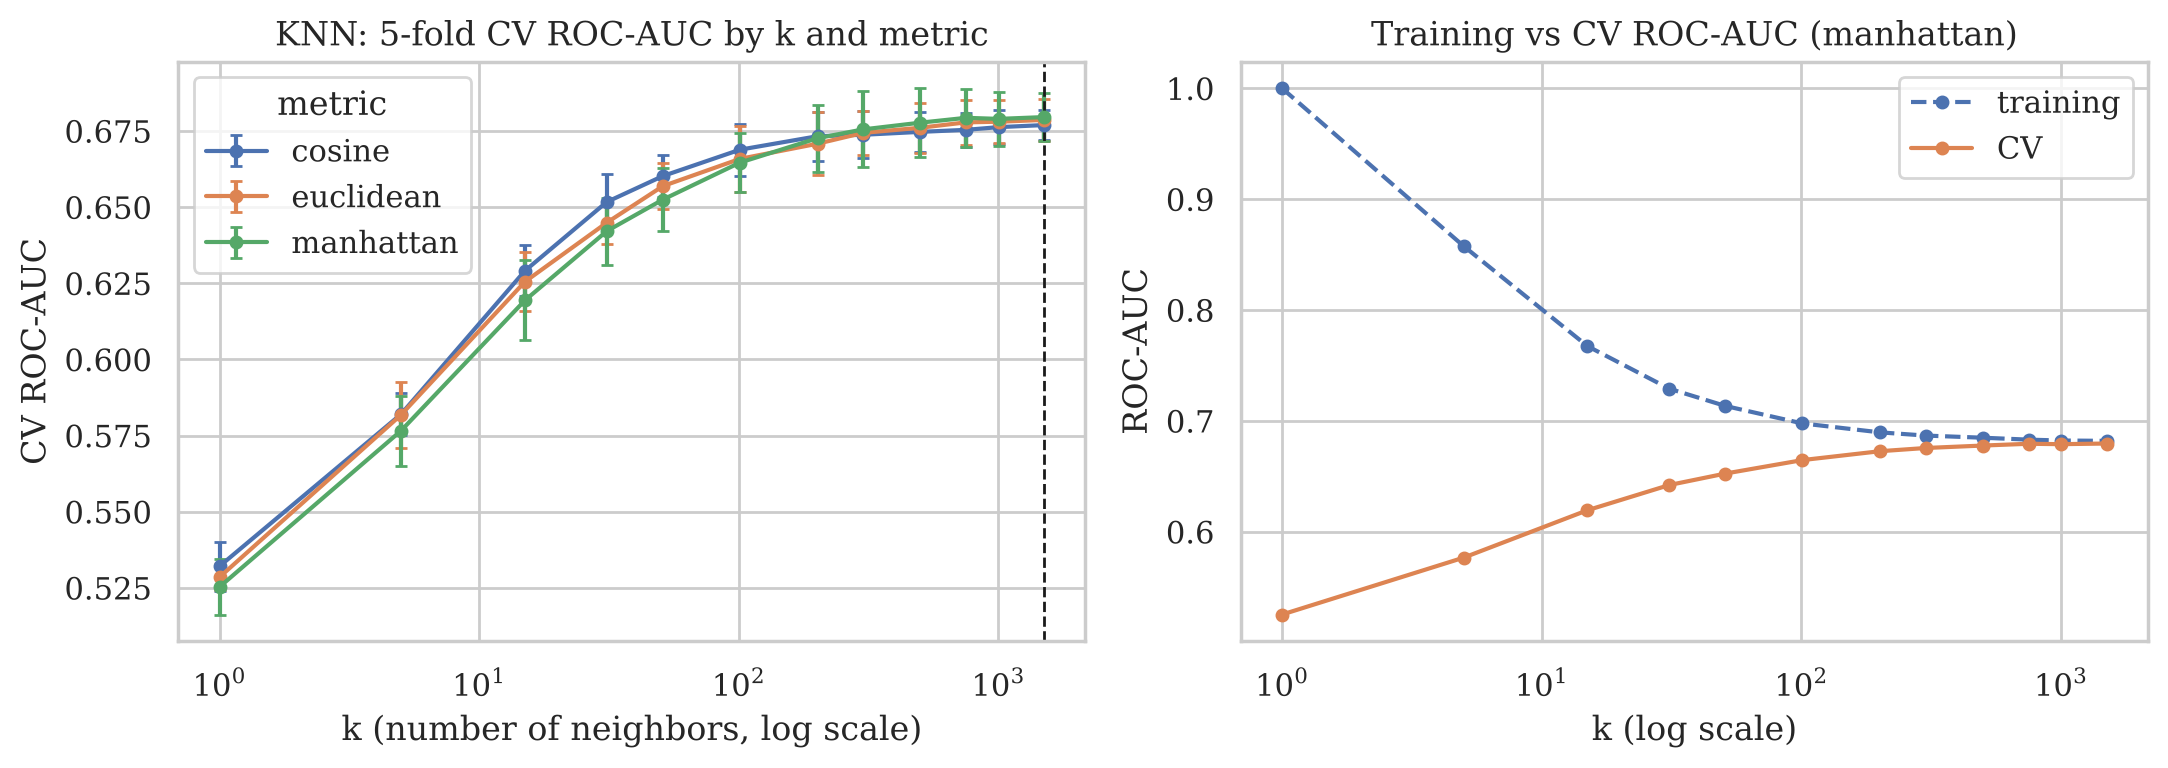

In [7]:
# Figure for the report: CV ROC-AUC vs k by metric, plus training vs CV for the best metric
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for m, g in cv_only.groupby("metric"):
    axes[0].errorbar(g["k"], g["roc_auc_mean"], yerr=g["roc_auc_std"], marker="o", ms=4, capsize=2, label=m)
axes[0].set(xscale="log", xlabel="k (number of neighbors, log scale)", ylabel="CV ROC-AUC", title="KNN: 5-fold CV ROC-AUC by k and metric")
axes[0].axvline(BEST_K, ls="--", c="k", lw=1); axes[0].legend(title="metric")
g = cvres[cvres.metric == BEST_METRIC]
for st, ls in [("train", "--"), ("CV", "-")]:
    gg = g[g["set"] == st]; axes[1].plot(gg["k"], gg["roc_auc_mean"], marker="o", ms=4, ls=ls, label="training" if st == "train" else "CV")
axes[1].set(xscale="log", xlabel="k (log scale)", ylabel="ROC-AUC", title=f"Training vs CV ROC-AUC ({BEST_METRIC})"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_knn_k_metric.png", dpi=200); plt.show()

## 4. Distance weighting and the curse of dimensionality

* `weights="distance"` lets closer neighbors count more. Every training loan is at distance 0 from itself, so its training score is its own label at any k — only cross-validated scores are meaningful.
* One-hot encoding turns 24 predictors into many dimensions. In high dimensions the nearest and farthest neighbors are at similar distances, so "nearest" carries less information. The tuned model is compared on all features and on six core risk features plus term.

In [8]:
CORE = ["int_rate", "fico", "dti", "log_annual_inc", "revol_util", "inq_last_6mths"]
core_pre = lambda: make_pre(True, CORE, ["term"])
core_tab, _ = knn_cv(Xs[CORE + ["term"]], ys, [BEST_K], BEST_METRIC, pre_fn=core_pre)
dist_w = cross_val_score(Pipeline([("pre", make_pre(True)), ("clf", knn(BEST_K, BEST_METRIC, "distance"))]), Xs, ys, cv=CV, scoring="roc_auc")
n_all = make_pre(True).fit(Xs).transform(Xs.head(5)).shape[1]
n_core = core_pre().fit(Xs[CORE + ["term"]]).transform(Xs[CORE + ["term"]].head(5)).shape[1]
dim_res = pd.DataFrame([
    {"variant": "all features, uniform", "dimensions": n_all, "CV_ROC_AUC": best["roc_auc_mean"], "sd": best["roc_auc_std"]},
    {"variant": "all features, distance-weighted", "dimensions": n_all, "CV_ROC_AUC": dist_w.mean(), "sd": dist_w.std()},
    {"variant": "6 core numeric + term, uniform", "dimensions": n_core, "CV_ROC_AUC": core_tab["roc_auc"].mean(), "sd": core_tab["roc_auc"].std()},
]).set_index("variant"); dim_res

,dimensions,CV_ROC_AUC,sd
variant,,,
"all features, uniform",48,0.6796,0.0079
"all features, distance-weighted",48,0.6798,0.0074
"6 core numeric + term, uniform",8,0.6758,0.0075


In [9]:
# Distance concentration: median ratio of nearest to farthest Euclidean distance for 200 query loans
Z = make_pre(True).fit(Xs).transform(Xs)
Zc = core_pre().fit(Xs[CORE + ["term"]]).transform(Xs[CORE + ["term"]])
rng = np.random.default_rng(RANDOM_STATE)
q, ref = rng.choice(len(Z), 200, replace=False), rng.choice(len(Z), 5_000, replace=False)
conc = {}
for name, M in [("all features", Z), ("core features", Zc)]:
    d = np.sqrt(((M[q][:, None, :] - M[ref][None, :, :]) ** 2).sum(-1)); d[d == 0] = np.nan
    conc[name] = np.nanmedian(np.nanmin(d, 1) / np.nanmax(d, 1))
    print(f"{name:14s} ({M.shape[1]:2d} dims): median nearest/farthest distance ratio = {conc[name]:.3f}")

all features   (48 dims): median nearest/farthest distance ratio = 0.162
core features  ( 8 dims): median nearest/farthest distance ratio = 0.047


## 5. Threshold (training data only) and held-out test evaluation

The threshold maximizes F1 on the out-of-fold predictions of the chosen model (Section 3), as in Weeks 4–6. A logistic regression (Week 4 settings: C = 0.1, unweighted) fitted on the **same 30,000 rows** separates the method from the smaller sample; the Week 4 model fitted on all 140,000 rows is the reference.

In [10]:
oof = OOF[BEST_METRIC][BEST_K]
prec, rec, thr = precision_recall_curve(ys, oof)
f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
THR = float(thr[np.nanargmax(f1[:-1])])
print(f"F1-optimal threshold from out-of-fold predictions: {THR:.3f}")
best_knn = Pipeline([("pre", make_pre(True)), ("clf", knn(BEST_K, BEST_METRIC))]).fit(Xs, ys)
t0 = time.time(); score_te = best_knn.predict_proba(X_te)[:, 1]; knn_pred_secs = time.time() - t0
score_tr = best_knn.predict_proba(Xs)[:, 1]

lr_same = Pipeline([("pre", ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median", add_indicator=True)), ("s", StandardScaler())]), NUM),
                                                ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.005, sparse_output=False), CAT)])),
                    ("clf", LogisticRegression(C=0.1, max_iter=5000))]).fit(Xs, ys)
lr_oof = cross_val_predict(lr_same, Xs, ys, cv=CV, method="predict_proba")[:, 1]
p2, r2, t2 = precision_recall_curve(ys, lr_oof); f2 = 2 * p2 * r2 / np.clip(p2 + r2, 1e-12, None)
LR_THR = float(t2[np.nanargmax(f2[:-1])])
lr_same_te = lr_same.predict_proba(X_te)[:, 1]

wk4 = pd.read_parquet(RES_DIR / "week4_logistic_test_scores.parquet").set_index("id").loc[test["id"].values]
rows = [{"model": f"KNN (k={BEST_K}, {BEST_METRIC}, {KNN_N:,} rows)", "train_ROC_AUC": roc_auc_score(ys, score_tr), "CV_ROC_AUC": best["roc_auc_mean"], **metrics(y_te, score_te, THR)},
        {"model": f"Logistic regression ({KNN_N:,} rows)", "train_ROC_AUC": roc_auc_score(ys, lr_same.predict_proba(Xs)[:, 1]), "CV_ROC_AUC": roc_auc_score(ys, lr_oof), **metrics(y_te, lr_same_te, LR_THR)},
        {"model": "Logistic regression (Week 4, 140,000 rows)", "train_ROC_AUC": np.nan, "CV_ROC_AUC": np.nan, **metrics(y_te, wk4["score"].values, float(wk4["threshold"].iloc[0]))}]
knn_test = pd.DataFrame(rows).set_index("model")
knn_test.to_csv(RES_DIR / "week8_knn_test_metrics.csv")
print(f"KNN scoring time for {len(X_te):,} test loans: {knn_pred_secs:.0f}s")
knn_test

F1-optimal threshold from out-of-fold predictions: 0.147


KNN scoring time for 60,000 test loans: 40s


,train_ROC_AUC,CV_ROC_AUC,ROC_AUC,PR_AUC(AP),accuracy,precision,recall,F1,threshold
model,,,,,,,,,
"KNN (k=1501, manhattan, 30,000 rows)",0.6823,0.6796,0.6764,0.2538,0.6051,0.2221,0.6617,0.3326,0.1466
"Logistic regression (30,000 rows)",0.6897,0.6843,0.6808,0.2585,0.6786,0.2429,0.5485,0.3367,0.1734
"Logistic regression (Week 4, 140,000 rows)",NaN,NaN,0.6821,0.2609,0.6639,0.2391,0.5777,0.3382,0.1671


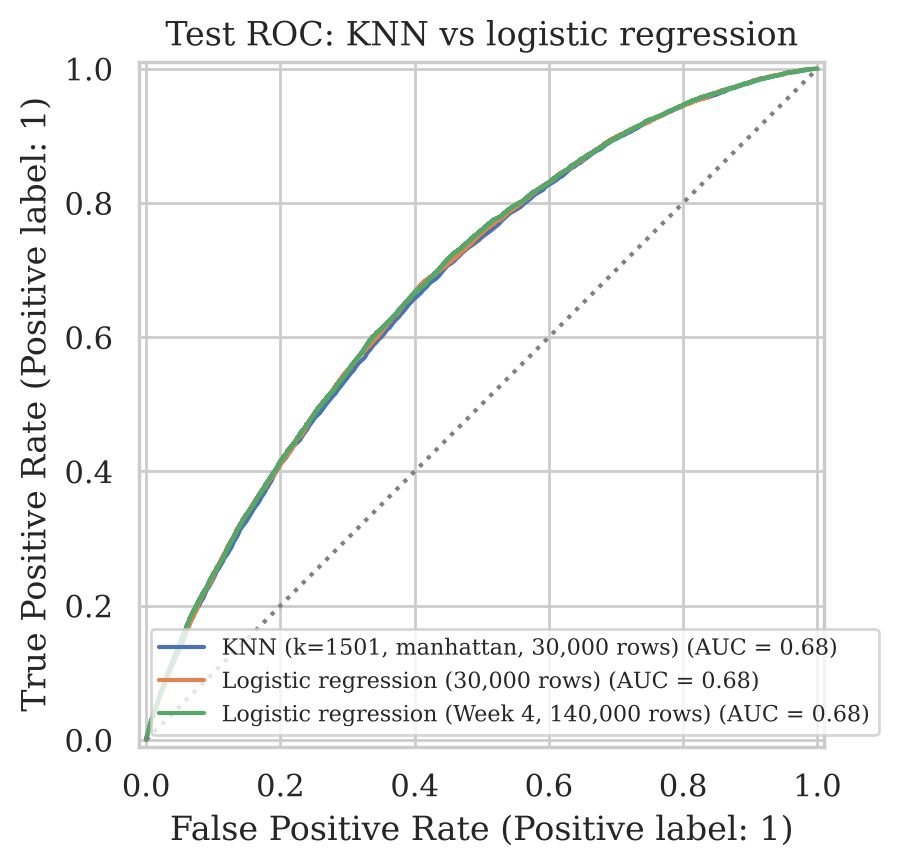

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, s in [(knn_test.index[0], score_te), (knn_test.index[1], lr_same_te), (knn_test.index[2], wk4["score"].values)]:
    RocCurveDisplay.from_predictions(y_te, s, ax=ax, name=name)
ax.plot([0, 1], [0, 1], ls=":", c="grey"); ax.set(title="Test ROC: KNN vs logistic regression"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "week8_knn_roc.png", dpi=200); plt.show()

In [12]:
pd.DataFrame({"id": test["id"].values, "y": y_te.values, "score": score_te, "threshold": THR}).to_parquet(RES_DIR / "week8_knn_test_scores.parquet", index=False)
summary = {"best_k": BEST_K, "best_metric": BEST_METRIC, "cv_auc": best["roc_auc_mean"], "threshold": THR, "knn_test_pred_seconds": knn_pred_secs,
           **{f"cv_seconds_{m}": v for m, v in secs.items()},
           **{f"scale_{f}_k{k}": scale_res.loc[k, ("mean", f)] for f in ["raw units", "standardized"] for k in SCALE_KS},
           **{f"concentration_{k}": v for k, v in conc.items()}}
pd.Series(summary).to_csv(RES_DIR / "week8_summary.csv")
pd.Series(summary)

best_k                              1501
best_metric                    manhattan
cv_auc                            0.6796
threshold                         0.1466
knn_test_pred_seconds            40.4378
cv_seconds_euclidean             27.1737
cv_seconds_manhattan             48.5821
cv_seconds_cosine                35.0092
scale_raw units_k15               0.5624
scale_raw units_k51               0.5845
scale_raw units_k201              0.5758
scale_standardized_k15            0.6255
scale_standardized_k51            0.6569
scale_standardized_k201           0.6708
concentration_all features        0.1624
concentration_core features       0.0473
dtype: object

## 6. Conclusions

**Scaling.** Unscaled, `loan_amnt` (sd ≈ 8,000) dominates every distance. At k = 201, standardizing raised CV ROC-AUC from 0.576 to 0.671; at every k tested, raw-unit KNN stayed below 0.59.

**k and overfitting.** k = 1 memorizes: training AUC 1.000, CV AUC 0.525–0.532. CV AUC rose steadily with k and flattened past about k = 500 (Manhattan: 0.678 at 501, 0.680 at 1,501), while the train–CV gap shrank from 0.47 to 0.002. The best k is at the edge of the grid, but the gain from 501 to 1,501 (0.002) is smaller than the CV standard deviation (0.008), so a larger grid would not change the conclusion. A very large neighborhood works best because the risk surface is smooth: the model is effectively averaging over broad regions, which is what a linear log-odds model already does.

**Distance metric.** The three metrics finished within 0.003 of each other at their best k (Manhattan 0.680, Euclidean 0.679, cosine 0.677), less than one CV standard deviation. Cosine was marginally best at small k and Manhattan at large k; the metric is not a meaningful lever on this data.

**Curse of dimensionality.** One-hot encoding gives 48 dimensions. The median nearest/farthest distance ratio is 0.162 in 48 dimensions vs. 0.047 with six core features plus term, so distances are more concentrated in the full space. Unexpectedly, the reduced set still scored slightly lower (0.676 vs. 0.680): the information lost by dropping features outweighed the cleaner distances. Distance weighting changed nothing (0.680).

**Test result.** KNN (k = 1,501, Manhattan, 30,000 rows) reached test ROC-AUC 0.676 and AP 0.254, below a logistic regression fitted on the same 30,000 rows (0.681) and the Week 4 model (0.682). Its train, CV and test AUC (0.682, 0.680, 0.676) agree, so it is not overfitting; it is simply a less efficient way to fit a smooth relationship, and it took 40 s to score 60,000 loans against 30,000 stored ones.

## Source for this week (shared on Yellowdig)

scikit-learn developers. (n.d.). *1.6. Nearest neighbors*. scikit-learn User Guide. https://scikit-learn.org/stable/modules/neighbors.html

**Why it is high quality:** The official user guide states the trade-off observed here — larger k suppresses noise but blurs class boundaries, and the optimal k is data-dependent — and explains brute-force vs. tree search, including why tree search loses its advantage as dimension grows (the curse of dimensionality).